In [ ]:
# ==============================
# CELL 1 — Imports & Setup
# ==============================

# Data handling
import numpy as np
import pandas as pd

# File loading (NASA data comes in .mat format — MATLAB files)
import scipy.io

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler

# Utility
import os
import warnings
warnings.filterwarnings("ignore")

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


In [ ]:
# ==============================
# CELL 2 — Download NASA Battery Dataset
# ==============================

import urllib.request
import zipfile
import os

# Create data folder
os.makedirs("data", exist_ok=True)

print("⏬ Downloading NASA battery dataset...")

# Working mirror of the official NASA dataset
url = "https://ssd.mathworks.com/supportfiles/predmaint/batteryagingdata/nasa/BatteryAgingData.zip"
urllib.request.urlretrieve(url, "data/BatteryAgingData.zip")

print("📦 Extracting files...")
with zipfile.ZipFile("data/BatteryAgingData.zip", 'r') as zip_ref:
    zip_ref.extractall("data/")

print("✅ Done! Let's check what we got:")
print(os.listdir("data/"))

⏬ Downloading NASA battery dataset...
📦 Extracting files...
✅ Done! Let's check what we got:
['BatteryAgingData.zip', 'B0007.mat', 'B0005.mat', 'B0006.mat']


In [ ]:
# ==============================
# CELL 3 — Load & Explore the Data
# ==============================

# Load the B0005 battery file
mat_data = scipy.io.loadmat('data/B0005.mat')

# The data is stored under the key 'B0005'
battery = mat_data['B0005']

# Let's see the structure
print("✅ B0005 loaded successfully!")
print("Type:", type(battery))
print("Fields inside:", battery.dtype.names)

✅ B0005 loaded successfully!
Type: <class 'numpy.ndarray'>
Fields inside: ('cycle',)


In [ ]:
# ==============================
# CELL 4 — Peek Inside the Cycles (Fixed)
# ==============================

# Get all the cycles correctly
cycles = battery['cycle'][0, 0].flatten()

# How many cycles does this battery have?
print("Total cycles recorded:", len(cycles))

# Look at what's inside one single cycle
print("\nFields inside each cycle:", cycles[0].dtype.names)

# Look at the first cycle
print("\nType of first cycle:", cycles[0]['type'][0][0])
print("Ambient temperature:", cycles[0]['ambient_temperature'][0][0])

Total cycles recorded: 599

Fields inside each cycle: ('type', 'ambient_temperature', 'time', 'data')

Type of first cycle: d
Ambient temperature: 24


In [ ]:
# ==============================
# CELL 5 — Explore Data Inside One Discharge Cycle
# ==============================

# Find the first DISCHARGE cycle (stored as 'd')
first_discharge = None
for i, cycle in enumerate(cycles):
    cycle_type = str(cycle['type'][0][0]).strip()
    if cycle_type == 'd':
        first_discharge = cycle
        print(f"✅ Found first discharge cycle at index: {i}")
        break

# What measurements are inside?
data = first_discharge['data'][0][0]
print("\nMeasurements inside a discharge cycle:", data.dtype.names)
print("\nVoltage readings (first 5):", data['Voltage_measured'][0][0].flatten()[:5])
print("Temperature readings (first 5):", data['Temperature_measured'][0][0].flatten()[:5])
print("Current readings (first 5):", data['Current_measured'][0][0].flatten()[:5])
print("Capacity:", data['Capacity'][0][0].flatten()[0])

✅ Found first discharge cycle at index: 0

Measurements inside a discharge cycle: ('Voltage_measured', 'Current_measured', 'Temperature_measured', 'Current_load', 'Voltage_load', 'Time', 'Capacity')

Voltage readings (first 5): [4.19149181]
Temperature readings (first 5): [24.33003389]
Current readings (first 5): [-0.00490159]
Capacity: 1.8564874208181574


In [ ]:
# ==============================
# CELL 6 — Extract Capacity from All Discharge Cycles
# ==============================

# We'll store cycle number and capacity for each discharge cycle
cycle_numbers = []
capacities = []

for i, cycle in enumerate(cycles):
    cycle_type = str(cycle['type'][0][0]).strip()

    # Only look at discharge cycles
    if cycle_type == 'd':
        capacity = cycle['data'][0][0]['Capacity'][0][0].flatten()[0]
        cycle_numbers.append(i)
        capacities.append(capacity)

print(f"✅ Total discharge cycles found: {len(cycle_numbers)}")
print(f"\nFirst capacity reading:  {capacities[0]:.4f} Ah")
print(f"Last capacity reading:   {capacities[-1]:.4f} Ah")
print(f"Total capacity lost:     {capacities[0] - capacities[-1]:.4f} Ah")
print(f"\nStarting capacity:       {capacities[0]:.4f} Ah")
print(f"EOL threshold (80%):     {capacities[0] * 0.8:.4f} Ah")

✅ Total discharge cycles found: 163

First capacity reading:  1.8565 Ah
Last capacity reading:   1.3090 Ah
Total capacity lost:     0.5475 Ah

Starting capacity:       1.8565 Ah
EOL threshold (80%):     1.4852 Ah


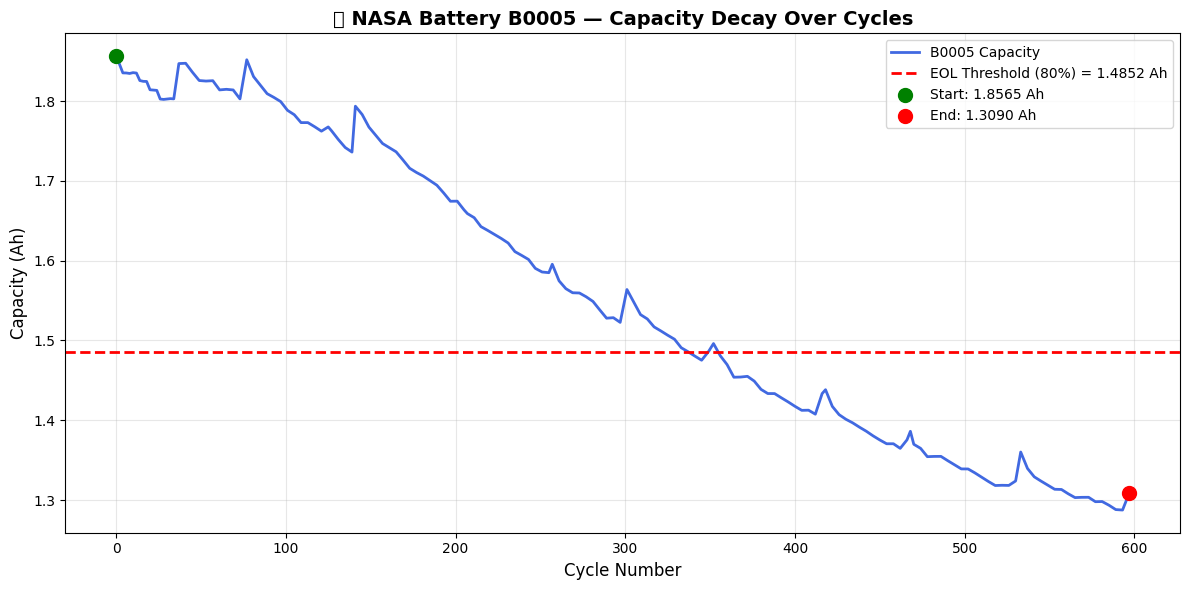

✅ Plot generated successfully!


In [ ]:
# ==============================
# CELL 7 — Plot Battery Capacity Decay
# ==============================

plt.figure(figsize=(12, 6))

# Plot the capacity over cycles
plt.plot(cycle_numbers, capacities, color='royalblue', linewidth=2, label='B0005 Capacity')

# Draw the EOL threshold line
eol_threshold = capacities[0] * 0.8
plt.axhline(y=eol_threshold, color='red', linestyle='--', linewidth=2, label=f'EOL Threshold (80%) = {eol_threshold:.4f} Ah')

# Mark the starting point
plt.scatter(cycle_numbers[0], capacities[0], color='green', s=100, zorder=5, label=f'Start: {capacities[0]:.4f} Ah')

# Mark the ending point
plt.scatter(cycle_numbers[-1], capacities[-1], color='red', s=100, zorder=5, label=f'End: {capacities[-1]:.4f} Ah')

# Labels and title
plt.title('🔋 NASA Battery B0005 — Capacity Decay Over Cycles', fontsize=14, fontweight='bold')
plt.xlabel('Cycle Number', fontsize=12)
plt.ylabel('Capacity (Ah)', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✅ Plot generated successfully!")

In [ ]:
# ==============================
# CELL 8 — Load All 3 Batteries
# ==============================

def load_battery(file_path, battery_name):
    """Load a battery .mat file and return its cycles"""
    mat_data = scipy.io.loadmat(file_path)
    battery = mat_data[battery_name]
    cycles = battery['cycle'][0, 0].flatten()
    print(f"✅ {battery_name} loaded — Total cycles: {len(cycles)}")
    return cycles

# Load all 3 batteries
cycles_B0005 = load_battery('data/B0005.mat', 'B0005')
cycles_B0006 = load_battery('data/B0006.mat', 'B0006')
cycles_B0007 = load_battery('data/B0007.mat', 'B0007')

print("\n✅ All batteries loaded successfully!")

✅ B0005 loaded — Total cycles: 599
✅ B0006 loaded — Total cycles: 599
✅ B0007 loaded — Total cycles: 599

✅ All batteries loaded successfully!


In [ ]:
# ==============================
# CELL 9 — Extract Features from All Batteries
# ==============================

def extract_features(cycles, battery_name):
    """Extract features from every discharge cycle of a battery"""

    records = []
    discharge_count = 0

    for i, cycle in enumerate(cycles):
        cycle_type = str(cycle['type'][0][0]).strip()

        if cycle_type == 'd':
            data = cycle['data'][0][0]

            voltage = data['Voltage_measured'][0][0].flatten()
            temperature = data['Temperature_measured'][0][0].flatten()
            time = data['Time'][0][0].flatten()
            capacity = data['Capacity'][0][0].flatten()[0]

            records.append({
                'battery':            battery_name,
                'cycle_index':        i,
                'discharge_number':   discharge_count,
                'capacity':           capacity,
                'voltage_min':        voltage.min(),
                'voltage_max':        voltage.max(),
                'voltage_range':      voltage.max() - voltage.min(),
                'temp_max':           temperature.max(),
                'temp_mean':          temperature.mean(),
                'discharge_duration': time.max() - time.min(),
            })
            discharge_count += 1

    df = pd.DataFrame(records)
    print(f"✅ {battery_name} — {len(df)} discharge cycles extracted")
    return df

# Extract features from all 3 batteries
df_B0005 = extract_features(cycles_B0005, 'B0005')
df_B0006 = extract_features(cycles_B0006, 'B0006')
df_B0007 = extract_features(cycles_B0007, 'B0007')

print("\n✅ Feature extraction complete!")

✅ B0005 — 163 discharge cycles extracted
✅ B0006 — 163 discharge cycles extracted
✅ B0007 — 163 discharge cycles extracted

✅ Feature extraction complete!


In [ ]:
# ==============================
# CELL 10 — Calculate RUL for Every Cycle
# ==============================

def calculate_rul(df):
    """Calculate Remaining Useful Life for each cycle"""

    # Find starting capacity (first cycle)
    initial_capacity = df['capacity'].iloc[0]

    # EOL threshold = 80% of initial capacity
    eol_threshold = initial_capacity * 0.8

    # Find the cycle where battery first drops below EOL threshold
    eol_cycles = df[df['capacity'] < eol_threshold]

    if len(eol_cycles) > 0:
        eol_index = eol_cycles.index[0]
        eol_discharge_number = df.loc[eol_index, 'discharge_number']
        print(f"  Battery: {df['battery'].iloc[0]}")
        print(f"  Initial capacity: {initial_capacity:.4f} Ah")
        print(f"  EOL threshold:    {eol_threshold:.4f} Ah")
        print(f"  EOL reached at discharge cycle: {eol_discharge_number}")
    else:
        eol_discharge_number = df['discharge_number'].max()
        print(f"  Battery: {df['battery'].iloc[0]} — EOL not reached!")

    # RUL = EOL cycle number - current cycle number
    df['RUL'] = eol_discharge_number - df['discharge_number']

    # Remove cycles after EOL (RUL can't be negative)
    df = df[df['RUL'] >= 0].copy()

    print(f"  Cycles kept (before EOL): {len(df)}\n")
    return df

# Calculate RUL for all batteries
print("Calculating RUL...\n")
df_B0005 = calculate_rul(df_B0005)
df_B0006 = calculate_rul(df_B0006)
df_B0007 = calculate_rul(df_B0007)

print("✅ RUL calculation complete!")

Calculating RUL...

  Battery: B0005
  Initial capacity: 1.8565 Ah
  EOL threshold:    1.4852 Ah
  EOL reached at discharge cycle: 96
  Cycles kept (before EOL): 97

  Battery: B0006
  Initial capacity: 2.0353 Ah
  EOL threshold:    1.6283 Ah
  EOL reached at discharge cycle: 58
  Cycles kept (before EOL): 59

  Battery: B0007
  Initial capacity: 1.8911 Ah
  EOL threshold:    1.5128 Ah
  EOL reached at discharge cycle: 119
  Cycles kept (before EOL): 120

✅ RUL calculation complete!


In [ ]:
# ==============================
# CELL 11 — Combine All Batteries into One Table
# ==============================

# Stack all 3 batteries into one DataFrame
df_all = pd.concat([df_B0005, df_B0006, df_B0007], ignore_index=True)

print("✅ Combined dataset shape:", df_all.shape)
print("\nBattery distribution:")
print(df_all['battery'].value_counts())

print("\nFirst 5 rows of our dataset:")
df_all.head()


✅ Combined dataset shape: (276, 11)

Battery distribution:
battery
B0007    120
B0005     97
B0006     59
Name: count, dtype: int64

First 5 rows of our dataset:


,battery,cycle_index,discharge_number,capacity,voltage_min,voltage_max,voltage_range,temp_max,temp_mean,discharge_duration,RUL
0,B0005,0,0,1.856487,4.191492,4.191492,0.0,24.330034,24.330034,0.0,96
1,B0005,2,1,1.846327,4.189773,4.189773,0.0,24.697752,24.697752,0.0,95
2,B0005,4,2,1.835349,4.188187,4.188187,0.0,24.734266,24.734266,0.0,94
3,B0005,6,3,1.835263,4.188461,4.188461,0.0,24.654236,24.654236,0.0,93
4,B0005,8,4,1.834646,4.188299,4.188299,0.0,24.524797,24.524797,0.0,92


In [ ]:
# ==============================
# CELL 12 — Train/Test Split
# ==============================

# Features we feed into the model
features = ['capacity', 'voltage_min', 'voltage_max',
            'voltage_range', 'temp_max', 'temp_mean',
            'discharge_duration']

# Target — what we want to predict
target = 'RUL'

# Train on B0005 + B0006
train_df = df_all[df_all['battery'].isin(['B0005', 'B0006'])]

# Test on B0007 (never seen by model)
test_df = df_all[df_all['battery'] == 'B0007']

X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("✅ Training set size:", X_train.shape)
print("✅ Testing set size:", X_test.shape)
print("\nTraining on: B0005 + B0006")
print("Testing on:  B0007 (unseen battery)")

✅ Training set size: (156, 7)
✅ Testing set size: (120, 7)

Training on: B0005 + B0006
Testing on:  B0007 (unseen battery)


In [ ]:
# ==============================
# CELL 13 — Train Random Forest Model
# ==============================

# Create the model
model = RandomForestRegressor(
    n_estimators=100,    # 100 decision trees
    random_state=42,     # for reproducibility
    max_depth=10         # how deep each tree can go
)

# Train it!
print("🤖 Training the model...")
model.fit(X_train, y_train)
print("✅ Model trained successfully!")

# Make predictions on B0007
y_pred = model.predict(X_test)

# Evaluate
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5

print(f"\n📊 Results on unseen battery B0007:")
print(f"   MAE  (Mean Absolute Error): {mae:.2f} cycles")
print(f"   RMSE (Root Mean Sq Error):  {rmse:.2f} cycles")
print(f"\n🧠 This means on average our model is off by {mae:.1f} cycles!")

🤖 Training the model...
✅ Model trained successfully!

📊 Results on unseen battery B0007:
   MAE  (Mean Absolute Error): 19.00 cycles
   RMSE (Root Mean Sq Error):  23.45 cycles

🧠 This means on average our model is off by 19.0 cycles!


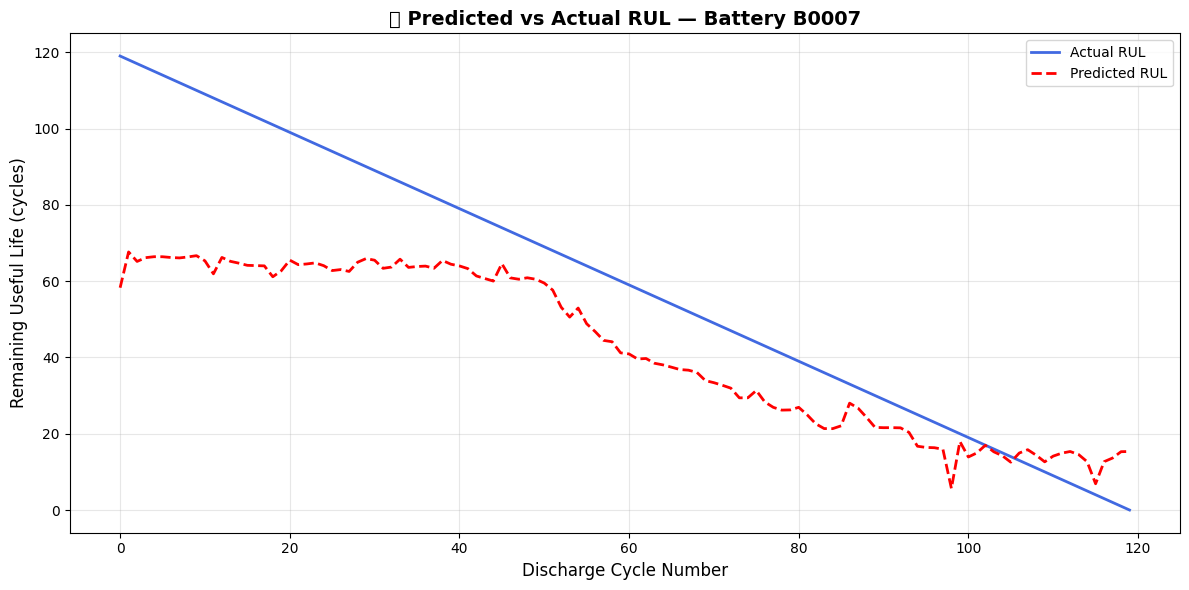

✅ MAE: 19.00 cycles | RMSE: 23.45 cycles


In [ ]:
# ==============================
# CELL 14 — Plot Predictions vs Actual
# ==============================

plt.figure(figsize=(12, 6))

# Plot actual RUL
plt.plot(test_df['discharge_number'].values,
         y_test.values,
         color='royalblue', linewidth=2, label='Actual RUL')

# Plot predicted RUL
plt.plot(test_df['discharge_number'].values,
         y_pred,
         color='red', linewidth=2,
         linestyle='--', label='Predicted RUL')

plt.title('🤖 Predicted vs Actual RUL — Battery B0007',
          fontsize=14, fontweight='bold')
plt.xlabel('Discharge Cycle Number', fontsize=12)
plt.ylabel('Remaining Useful Life (cycles)', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"✅ MAE: {mae:.2f} cycles | RMSE: {rmse:.2f} cycles")

In [ ]:
# ==============================
# CELL 15 — Add Better Features
# ==============================

def add_trend_features(df):
    """Add trend-based features to capture battery aging"""

    # Sort by discharge number
    df = df.sort_values('discharge_number').copy()

    # 1. Capacity drop from starting capacity
    initial_cap = df['capacity'].iloc[0]
    df['capacity_drop'] = initial_cap - df['capacity']

    # 2. Capacity fade rate (rolling average over last 5 cycles)
    df['capacity_fade_rate'] = df['capacity'].diff(5) / 5
    df['capacity_fade_rate'] = df['capacity_fade_rate'].fillna(0)

    # 3. State of Health (SOH) — capacity as % of original
    df['SOH'] = df['capacity'] / initial_cap * 100

    # 4. Discharge number itself (age of battery)
    # already exists as 'discharge_number'

    return df

# Apply to all batteries
df_B0005 = add_trend_features(df_B0005)
df_B0006 = add_trend_features(df_B0006)
df_B0007 = add_trend_features(df_B0007)

# Recombine
df_all = pd.concat([df_B0005, df_B0006, df_B0007], ignore_index=True)

print("✅ New features added!")
print("\nAll features now available:")
print([col for col in df_all.columns if col not in ['battery', 'cycle_index', 'RUL']])

✅ New features added!

All features now available:
['discharge_number', 'capacity', 'voltage_min', 'voltage_max', 'voltage_range', 'temp_max', 'temp_mean', 'discharge_duration', 'capacity_drop', 'capacity_fade_rate', 'SOH']


In [ ]:
# ==============================
# CELL 16 — Retrain Model with Better Features
# ==============================

# Updated feature list with new features
features = ['capacity', 'voltage_min', 'voltage_max',
            'voltage_range', 'temp_max', 'temp_mean',
            'discharge_duration', 'discharge_number',
            'capacity_drop', 'capacity_fade_rate', 'SOH']

target = 'RUL'

# Train on B0005 + B0006
train_df = df_all[df_all['battery'].isin(['B0005', 'B0006'])]
test_df  = df_all[df_all['battery'] == 'B0007']

X_train = train_df[features]
y_train = train_df[target]
X_test  = test_df[features]
y_test  = test_df[target]

# Train improved model
model_v2 = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    max_depth=15
)

print("🤖 Training improved model...")
model_v2.fit(X_train, y_train)
y_pred_v2 = model_v2.predict(X_test)

# Compare results
mae_v2  = mean_absolute_error(y_test, y_pred_v2)
rmse_v2 = mean_squared_error(y_test, y_pred_v2) ** 0.5

print(f"\n📊 OLD model — MAE: {mae:.2f} | RMSE: {rmse:.2f}")
print(f"📊 NEW model — MAE: {mae_v2:.2f} | RMSE: {rmse_v2:.2f}")

improvement = mae - mae_v2
print(f"\n✅ Improvement: {improvement:.2f} cycles better!")

🤖 Training improved model...

📊 OLD model — MAE: 19.00 | RMSE: 23.45
📊 NEW model — MAE: 19.16 | RMSE: 20.44

✅ Improvement: -0.16 cycles better!


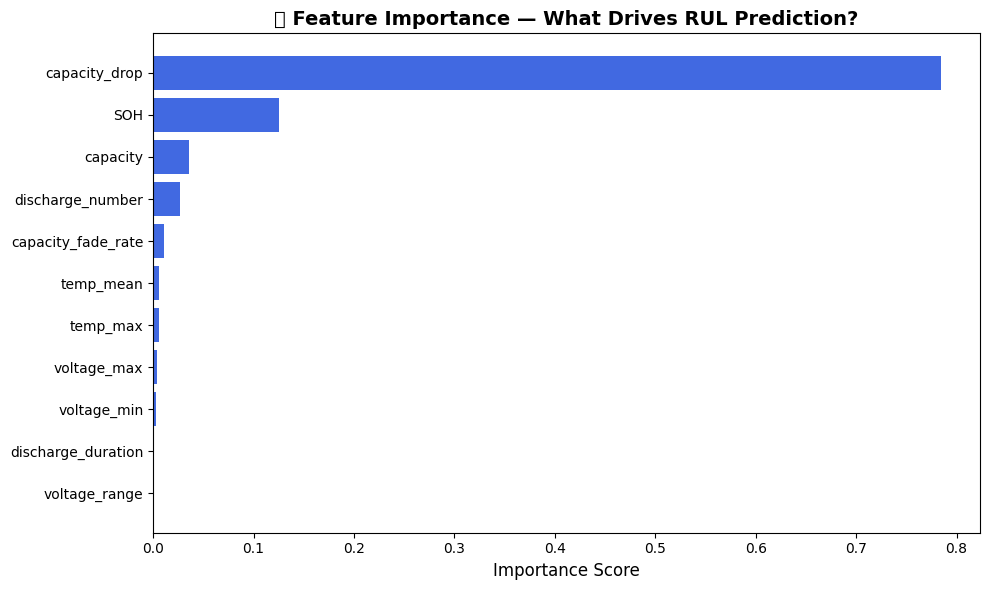

✅ Feature importance chart done!


In [ ]:
# ==============================
# CELL 17 — Feature Importance Chart
# ==============================

importances = model_v2.feature_importances_
feat_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values('Importance', ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(feat_df['Feature'], feat_df['Importance'], color='royalblue')
plt.title('🔍 Feature Importance — What Drives RUL Prediction?',
          fontsize=14, fontweight='bold')
plt.xlabel('Importance Score', fontsize=12)
plt.tight_layout()
plt.show()

print("✅ Feature importance chart done!")

In [ ]:
# ==============================
# CELL 18 — Compare Multiple Models
# ==============================

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler

# Features and target
features = ['capacity', 'voltage_min', 'voltage_max',
            'voltage_range', 'temp_max', 'temp_mean',
            'discharge_duration', 'discharge_number',
            'capacity_drop', 'capacity_fade_rate', 'SOH']

target = 'RUL'

# Train/test split
train_df = df_all[df_all['battery'].isin(['B0005', 'B0006'])]
test_df  = df_all[df_all['battery'] == 'B0007']

X_train = train_df[features]
y_train = train_df[target]
X_test  = test_df[features]
y_test  = test_df[target]

# Define all models to compare
models = {
    'Linear Regression':    LinearRegression(),
    'Random Forest':        RandomForestRegressor(n_estimators=200, random_state=42, max_depth=15),
    'Gradient Boosting':    GradientBoostingRegressor(n_estimators=200, random_state=42, max_depth=5)
}

# Train and evaluate each model
results = []
predictions = {}

print("🤖 Training and comparing models...\n")

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    mae  = mean_absolute_error(y_test, y_pred)
    rmse = mean_squared_error(y_test, y_pred) ** 0.5

    results.append({'Model': name, 'MAE': round(mae, 2), 'RMSE': round(rmse, 2)})
    predictions[name] = y_pred

    print(f"✅ {name}")
    print(f"   MAE:  {mae:.2f} cycles")
    print(f"   RMSE: {rmse:.2f} cycles\n")

# Show results as a table
results_df = pd.DataFrame(results).sort_values('MAE')
print("🏆 Model Ranking (by MAE):")
print(results_df.to_string(index=False))

🤖 Training and comparing models...

✅ Linear Regression
   MAE:  30.34 cycles
   RMSE: 30.34 cycles

✅ Random Forest
   MAE:  19.16 cycles
   RMSE: 20.44 cycles

✅ Gradient Boosting
   MAE:  18.58 cycles
   RMSE: 19.71 cycles

🏆 Model Ranking (by MAE):
            Model   MAE  RMSE
Gradient Boosting 18.58 19.71
    Random Forest 19.16 20.44
Linear Regression 30.34 30.34


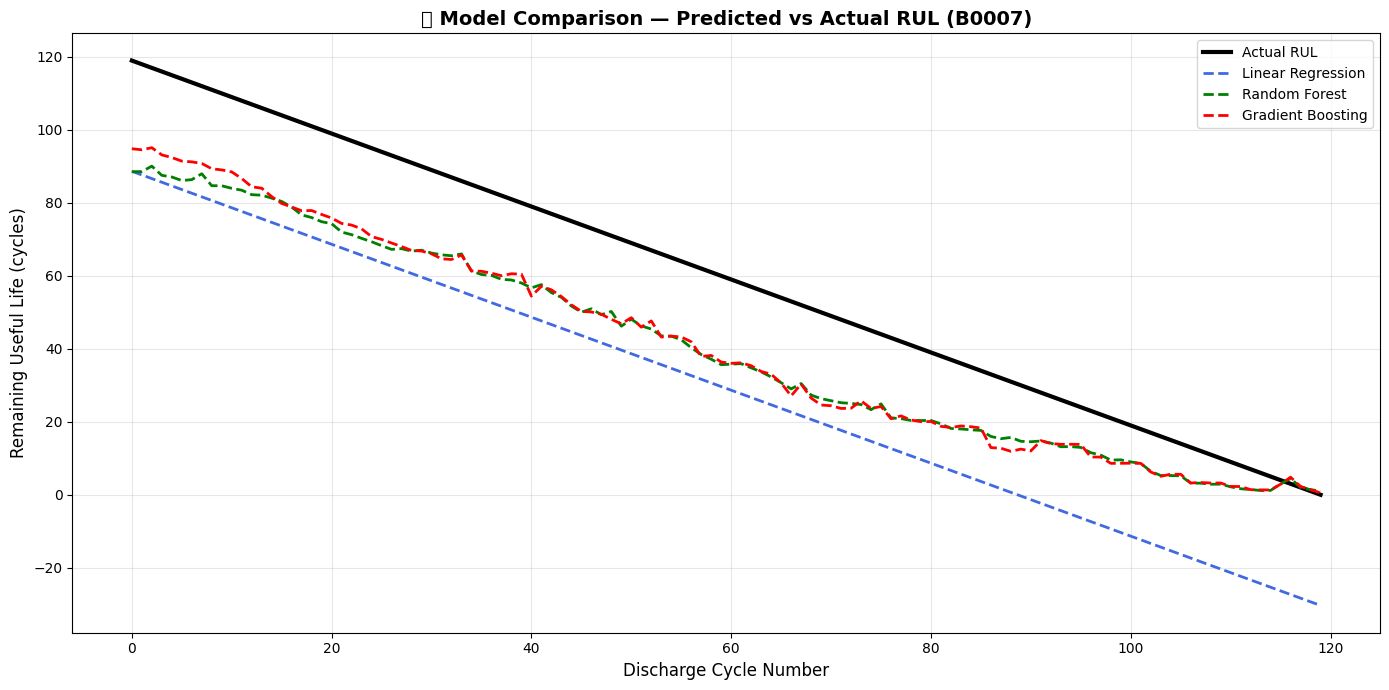

✅ Model comparison chart done!


In [ ]:
# ==============================
# CELL 19 — Compare All Models Visually
# ==============================

plt.figure(figsize=(14, 7))

# Plot actual RUL
plt.plot(test_df['discharge_number'].values,
         y_test.values,
         color='black', linewidth=3, label='Actual RUL')

# Plot each model's predictions
colors = ['royalblue', 'green', 'red']
for (name, y_pred), color in zip(predictions.items(), colors):
    plt.plot(test_df['discharge_number'].values,
             y_pred,
             linewidth=2, linestyle='--',
             color=color, label=f'{name}')

plt.title('🤖 Model Comparison — Predicted vs Actual RUL (B0007)',
          fontsize=14, fontweight='bold')
plt.xlabel('Discharge Cycle Number', fontsize=12)
plt.ylabel('Remaining Useful Life (cycles)', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("✅ Model comparison chart done!")

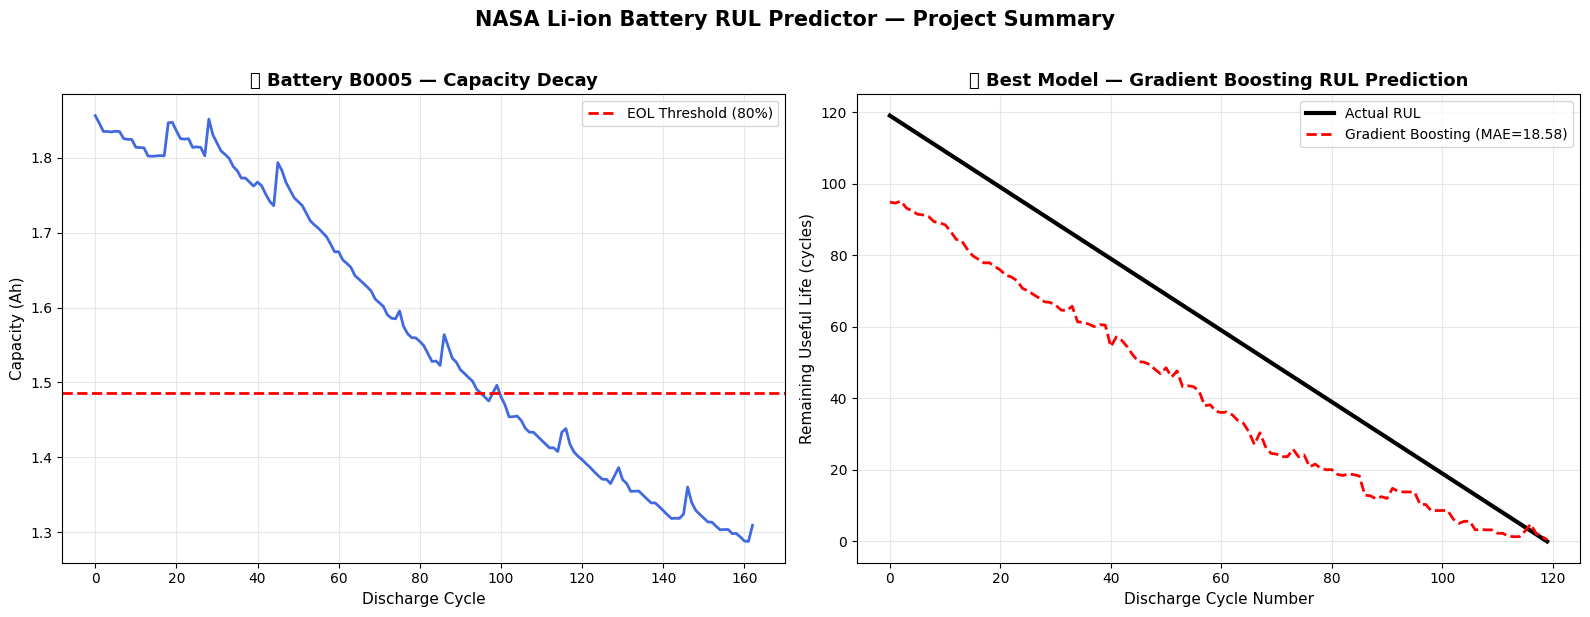

✅ Final summary chart done!


In [ ]:
# ==============================
# CELL 20 — Final Summary Chart
# ==============================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Chart 1: Capacity Decay ---
axes[0].plot(range(len(capacities)), capacities,
             color='royalblue', linewidth=2)
axes[0].axhline(y=capacities[0]*0.8, color='red',
                linestyle='--', linewidth=2, label='EOL Threshold (80%)')
axes[0].set_title('🔋 Battery B0005 — Capacity Decay',
                  fontsize=13, fontweight='bold')
axes[0].set_xlabel('Discharge Cycle', fontsize=11)
axes[0].set_ylabel('Capacity (Ah)', fontsize=11)
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

# --- Chart 2: Best Model Predictions ---
axes[1].plot(test_df['discharge_number'].values,
             y_test.values,
             color='black', linewidth=3, label='Actual RUL')
axes[1].plot(test_df['discharge_number'].values,
             predictions['Gradient Boosting'],
             color='red', linewidth=2,
             linestyle='--', label=f'Gradient Boosting (MAE=18.58)')
axes[1].set_title('🤖 Best Model — Gradient Boosting RUL Prediction',
                  fontsize=13, fontweight='bold')
axes[1].set_xlabel('Discharge Cycle Number', fontsize=11)
axes[1].set_ylabel('Remaining Useful Life (cycles)', fontsize=11)
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.suptitle('NASA Li-ion Battery RUL Predictor — Project Summary',
             fontsize=15, fontweight='bold', y=1.02)

plt.tight_layout()
plt.show()

print("✅ Final summary chart done!")